Найкраще значення K: 3
Найкраща точність: 100.00%


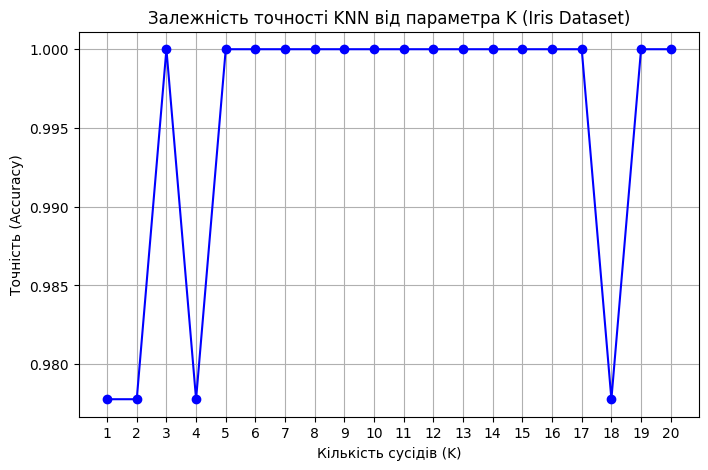

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.datasets import make_blobs
from matplotlib.colors import ListedColormap

# 1. Завантаження датасету
# Додаємо назви колонок, оскільки в файлі їх немає
columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class']
df = pd.read_csv('IrisData_full.csv', names=columns)

# 2. Відділяємо ознаки (X) від цільової змінної (y)
X = df.drop('class', axis=1).values
y = df['class'].values

# 3. Нормалізація параметрів
scaler = StandardScaler()
X_normalized = scaler.fit_transform(X)

# 4. Розділення та перемішування на навчальну (70%) і тестові вибірки (30%)
X_train, X_test, y_train, y_test = train_test_split(X_normalized, y, test_size=0.3, random_state=42, shuffle=True)

# 5. Навчання KNN-класифікатора з різними значеннями K
best_k = 0
best_accuracy = 0
accuracies = []

for k in range(1, 21):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    accuracy = knn.score(X_test, y_test)
    accuracies.append(accuracy)

    # Шукаємо найкраще K
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_k = k

print(f"Найкраще значення K: {best_k}")
print(f"Найкраща точність: {best_accuracy * 100:.2f}%")

# Побудова графіка
plt.figure(figsize=(8, 5))
plt.plot(range(1, 21), accuracies, marker='o', color='blue')
plt.title('Залежність точності KNN від параметра K (Iris Dataset)')
plt.xlabel('Кількість сусідів (K)')
plt.ylabel('Точність (Accuracy)')
plt.xticks(range(1, 21))
plt.grid(True)
plt.show()

Синтетичні дані (Регресія) - Найкраще K: 5, R2 Score: 0.9848


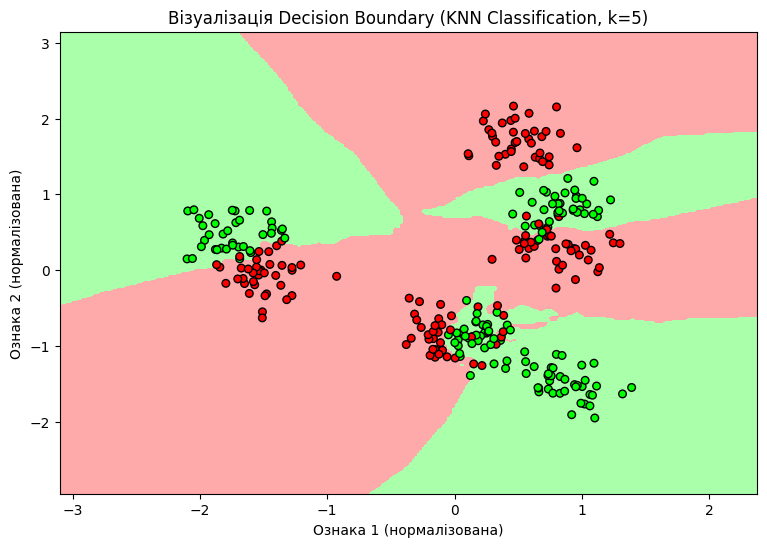

In [2]:
# 1. Генерація синтетичного датасету
np.random.seed(2021)
X_syn, y_syn = make_blobs(n_samples=300, n_features=2, centers=8, cluster_std=1.3, random_state=4)

# Створюємо мітки для бінарної класифікації (парні/непарні кластери) та неперервні для регресії
y_syn_class = y_syn % 2
y_syn_reg = 2 * X_syn[:, 0] + 3 * X_syn[:, 1] + np.random.randn(300) * 2

# 2. Нормалізація та перемішування
scaler_syn = StandardScaler()
X_syn_norm = scaler_syn.fit_transform(X_syn)
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_syn_norm, y_syn_reg, test_size=0.3, random_state=42, shuffle=True)

# 3. Навчання KNN регресора з різними K
best_k_reg = 0
best_score = -float('inf')
scores_reg = []

for k in range(1, 30):
    knn_reg = KNeighborsRegressor(n_neighbors=k)
    knn_reg.fit(X_train_s, y_train_s)
    score = knn_reg.score(X_test_s, y_test_s)
    scores_reg.append(score)
    if score > best_score:
        best_score = score
        best_k_reg = k

print(f"Синтетичні дані (Регресія) - Найкраще K: {best_k_reg}, R2 Score: {best_score:.4f}")

# 4. Візуалізація Decision Boundary (межі прийняття рішень для класифікації)
knn_best_class = KNeighborsClassifier(n_neighbors=5) # Беремо k=5 для наочності
knn_best_class.fit(X_syn_norm, y_syn_class)

# Налаштування сітки для графіка
x_min, x_max = X_syn_norm[:, 0].min() - 1, X_syn_norm[:, 0].max() + 1
y_min, y_max = X_syn_norm[:, 1].min() - 1, X_syn_norm[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

Z = knn_best_class.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00'])

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z, cmap=cmap_light)
plt.scatter(X_syn_norm[:, 0], X_syn_norm[:, 1], c=y_syn_class, cmap=cmap_bold, edgecolor='k', s=30)
plt.title(f'Візуалізація Decision Boundary (KNN Classification, k=5)')
plt.xlabel('Ознака 1 (нормалізована)')
plt.ylabel('Ознака 2 (нормалізована)')
plt.show()